# Practical Lab 2: Multivariate Linear Regression, Non-Parametric Models and Cross-Validation

## Part 1: Data Exploration and Preparation

### Step 1: Load the Diabetes Dataset

In [1]:
# Import the required libraries
import pandas as pd
import numpy as np

from sklearn.datasets import load_diabetes

# Load the diabetes dataset
diabetes = load_diabetes(as_frame=True)

# Convert the dataset into a Pandas DataFrame
df = diabetes.frame.copy()

# Display basic information
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

# Display the first 5 rows
df.head()

Dataset Shape: (442, 11)

Column Names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


### Step 2: Problem Framing

#### Problem Statement
The objective of this lab is to develop and compare machine
learning models to predict diabetes disease progression one
year after baseline using patient health information.

#### Input Features
The dataset contains 10 features, including age, sex,
BMI, blood pressure, and six blood serum measurements.

#### Target Variable
The target is a continuous numerical measure of diabetes
disease progression one year after baseline.

#### Dataset Description and Reference

The Scikit-learn Diabetes dataset contains 442
patients with diabetes and 10 baseline input features,
including age, sex, BMI, blood pressure, and six
blood serum measurements.

The target is a quantitative measure of diabetes
disease progression one year after baseline.

The input features are scaled by default.

This project predicts diabetes progression scores,
not whether a patient will develop diabetes.

**Reference:**
[Scikit-learn Diabetes Dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset)

#### Machine Learning Approach
This is primarily a supervised regression problem because
the target variable is numerical.

We will compare polynomial regression, decision trees,
and K-Nearest Neighbors (kNN). Logistic Regression will
also be explored as a classification approach, which
requires converting the target into categories.

#### Model Evaluation
We will evaluate regression models using:

- R²: Measures how well the model explains target variation.
- MAE: Measures the average absolute prediction error.
- MAPE: Measures average percentage prediction error.

Training, validation, and test datasets will be used to
compare models and evaluate generalization to unseen data.

#### Practical Considerations
Different models may perform differently depending on
the complexity of the relationships in the dataset.

As discussed in previous classification and kNN workshops,
model selection should consider generalization, overfitting,
and appropriate evaluation metrics.

The dataset is educational, and results should not be
interpreted as a clinically validated screening tool.

### Step 3: Exploratory Data Analysis (EDA)

#### Step 3.1: Dataset Structure and Descriptive Statistics

**Objective:** Examine the dataset structure, data types,
descriptive statistics, and completeness before developing
machine learning models.

In [2]:
# Step 3.1: Explore the dataset structure

print("Dataset Information:")
df.info()

print("\nDescriptive Statistics:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Descriptive Statistics:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000



Missing Values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64


##### Observations

- The dataset contains 442 patient records and 11 columns,
  consisting of 10 input features and one target variable.
- All columns are stored as float64 numerical values.
- Every column contains 442 non-null observations,
  indicating that no missing values are present.
- The input features have means approximately equal to zero
  because the dataset is scaled by default.
- The feature values do not represent original clinical
  measurements such as actual age or BMI.
- The descriptive statistics provide information about
  central tendency, variability, and feature ranges.

##### Key Insights

1. **Data Completeness:** No missing values were identified,
   so missing-value imputation is not required.

2. **Feature Scaling:** The input features are already
   scaled, which is useful for distance-based models
   such as K-Nearest Neighbors (kNN).

3. **Data Interpretation:** Scaled values must be interpreted
   carefully because they differ from original patient
   measurements.

4. **Further Investigation:** Histograms, scatter plots,
   and correlation analysis are needed to understand
   distributions, potential outliers, and relationships
   with diabetes progression.

##### Conclusion

The dataset is complete and suitable for further exploratory
analysis. Additional checks for duplicates, unusual values,
and feature relationships will help determine whether
further cleaning is necessary.

#### Step 3.2: Distribution of Diabetes Progression

**Objective:** Examine the distribution of the target variable
using a histogram.

The histogram displays the frequency of different diabetes
progression scores.

This analysis helps identify:
- The most frequently observed progression ranges.
- Whether scores are evenly or unevenly distributed.
- Possible skewness in the distribution.
- Potential extreme values that may affect model performance.

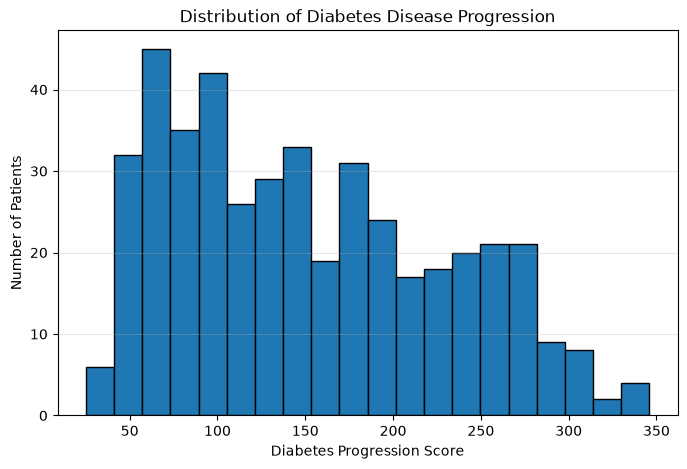

In [3]:
import matplotlib.pyplot as plt

# Plot distribution of diabetes progression
plt.figure(figsize=(8, 5))

plt.hist(df["target"], bins=20, edgecolor="black")

plt.title("Distribution of Diabetes Disease Progression")
plt.xlabel("Diabetes Progression Score")
plt.ylabel("Number of Patients")

plt.grid(axis="y", alpha=0.3)
plt.show()

#### Step 3.3: Distribution of Input Features

**Objective:** Explore the distributions of the ten input
features using histograms.

Histograms help us understand the frequency and spread
of feature values across the dataset.

This analysis focuses on:
- Distribution patterns of individual features.
- Skewness and variation in feature values.
- Potential extreme values.
- Differences between continuous and encoded features.

Understanding these distributions is useful for selecting
appropriate preprocessing techniques and machine learning
models.

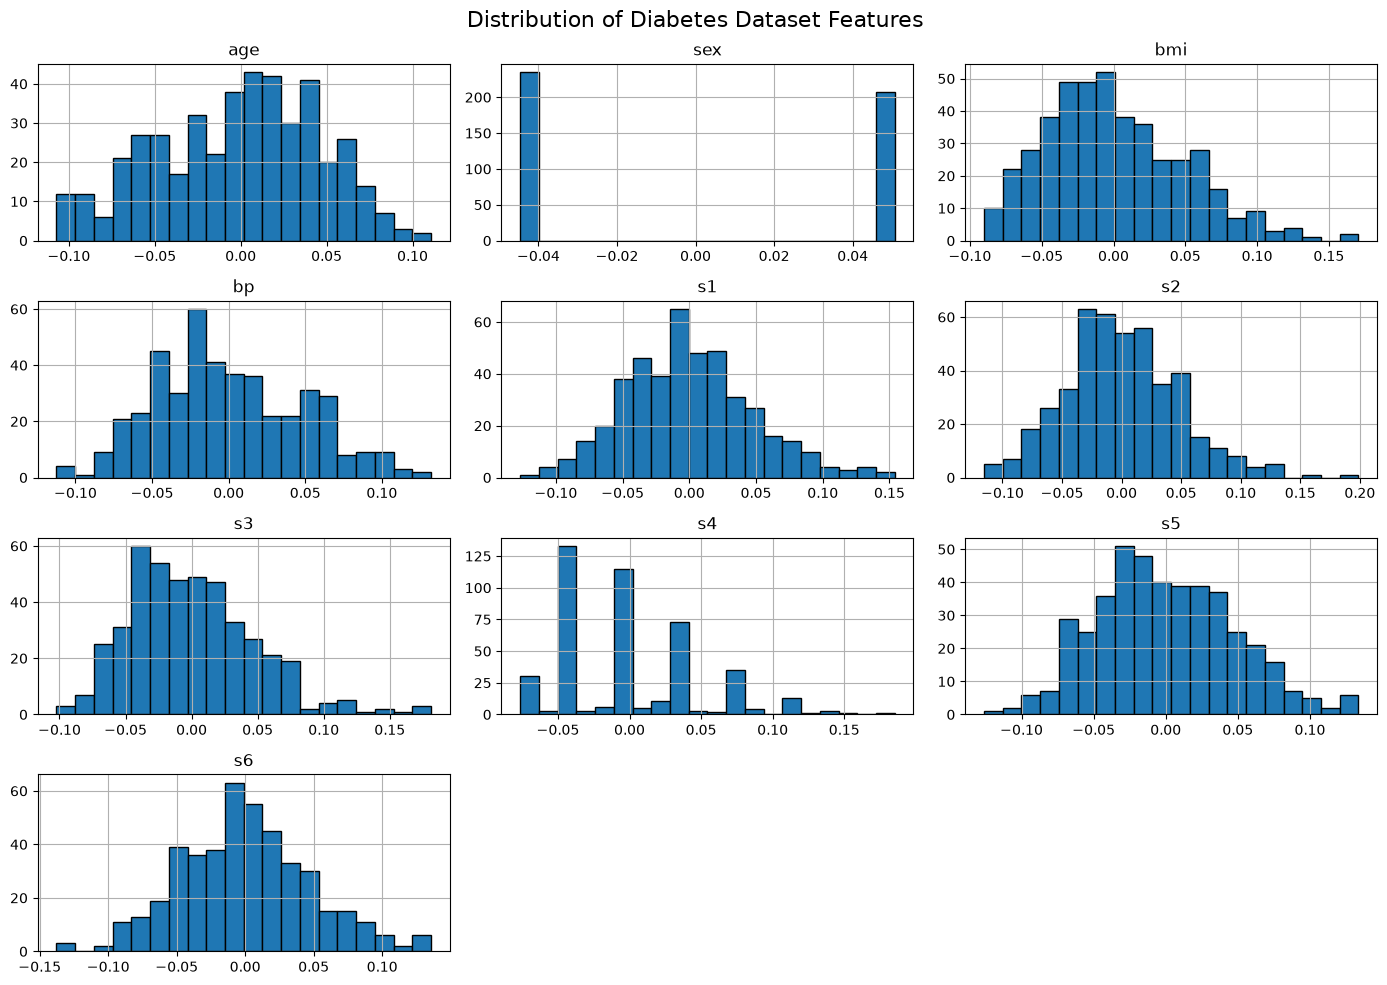

In [4]:
# Step 3.3: Distribution of Input Features

# Select all input features, excluding the target
features = df.drop(columns=["target"])

# Create histograms for all 10 features
features.hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

# Add a main title
plt.suptitle("Distribution of Diabetes Dataset Features", fontsize=16)

# Adjust spacing between plots
plt.tight_layout()

# Display the plots
plt.show()

#### Step 3.4: Scatter Plot Analysis

**Objective:** Explore the relationship between BMI and
diabetes disease progression using a scatter plot.

The scatter plot helps identify possible linear or
non-linear relationships, trends, and unusual observations.

BMI is particularly important because it will be used
as the independent variable in the univariate polynomial
regression models developed in Part 2.

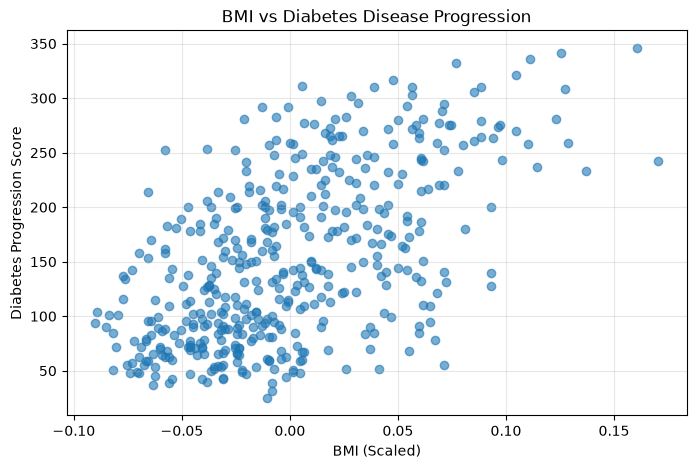

In [5]:
# Step 3.4: BMI vs Diabetes Progression

plt.figure(figsize=(8, 5))

# Create scatter plot
plt.scatter(
    df["bmi"],
    df["target"],
    alpha=0.6
)

# Add labels and title
plt.title("BMI vs Diabetes Disease Progression")
plt.xlabel("BMI (Scaled)")
plt.ylabel("Diabetes Progression Score")

plt.grid(alpha=0.3)
plt.show()

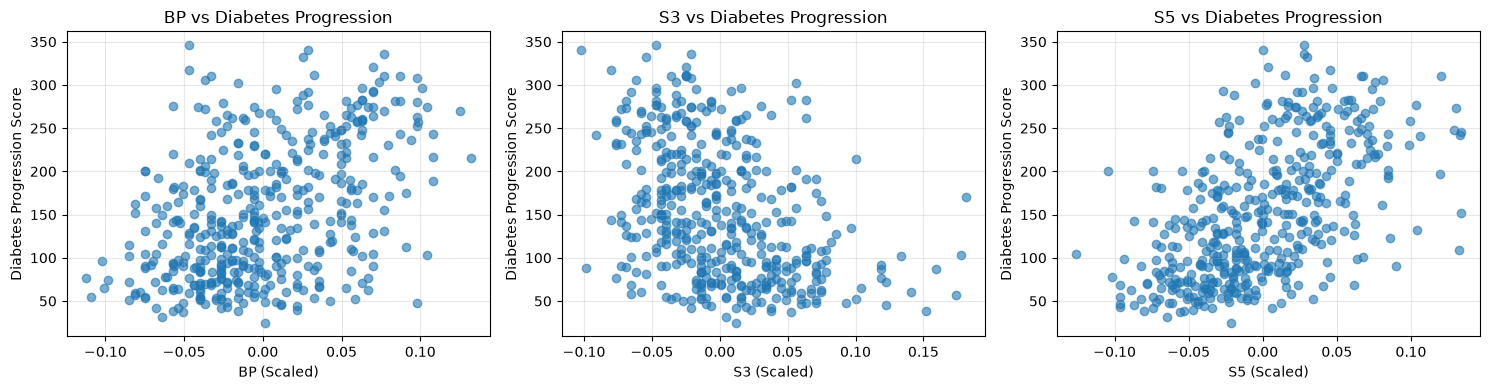

In [6]:
# Step 3.4: Additional Feature vs Target Scatter Plots

selected_features = ["bp", "s3", "s5"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, feature in enumerate(selected_features):
    axes[i].scatter(
        df[feature],
        df["target"],
        alpha=0.6
    )

    axes[i].set_title(f"{feature.upper()} vs Diabetes Progression")
    axes[i].set_xlabel(f"{feature.upper()} (Scaled)")
    axes[i].set_ylabel("Diabetes Progression Score")
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

##### Additional Feature Relationships

**Objective:** Investigate how blood pressure and selected
serum measurements relate to diabetes progression.

Scatter plots for bp, s3, and s5 are used to examine
the direction, strength, and possible nonlinearity of
relationships with the target variable.

This analysis helps identify potentially useful features
for the multivariate models developed in Part 3.

#### Step 3.5: Correlation Matrix Analysis

**Objective:** Analyze the linear relationships between
the input features and diabetes progression using a
Pearson correlation matrix.

The correlation matrix helps identify:
- Features positively associated with diabetes progression.
- Features negatively associated with diabetes progression.
- Strong correlations between input features that may
  indicate multicollinearity.
- Potentially useful predictors for multivariate models.

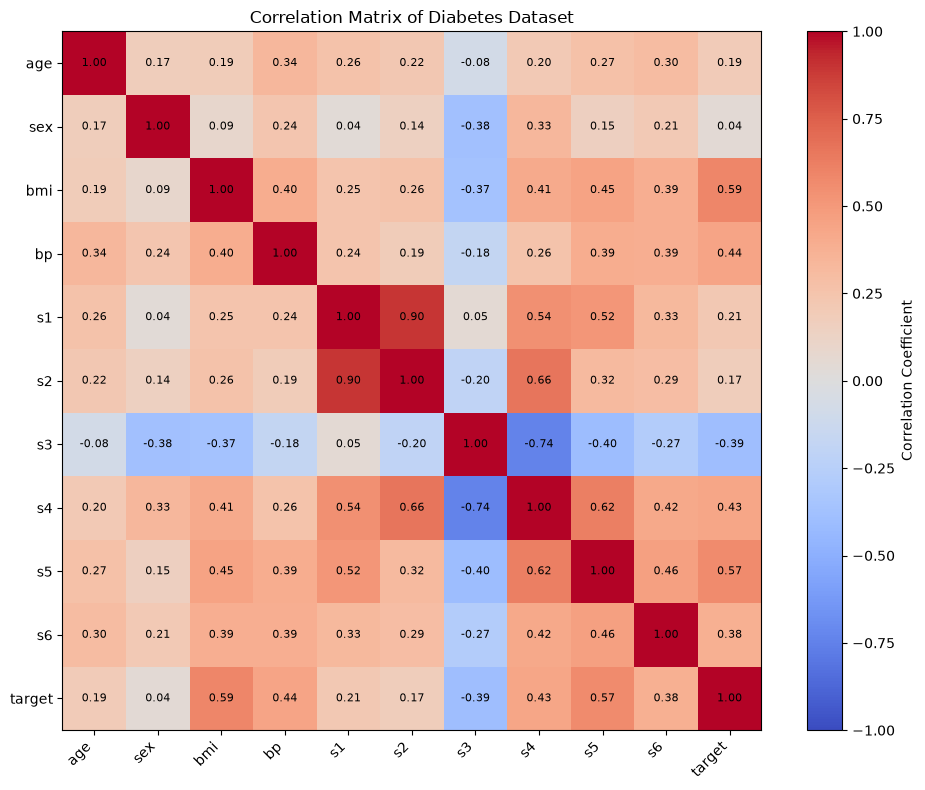

Feature Correlations with Diabetes Progression:
bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043
s3    -0.395
Name: target, dtype: float64


In [7]:
# Step 3.5: Correlation Matrix

# Calculate correlation between all numerical columns
corr_matrix = df.corr()

# Create the heatmap
fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

# Display column labels
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))

ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right")
ax.set_yticklabels(corr_matrix.columns)

# Display correlation values inside each cell
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix.columns)):
        ax.text(
            j, i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

# Add color scale and title
plt.colorbar(im, ax=ax, label="Correlation Coefficient")
plt.title("Correlation Matrix of Diabetes Dataset")

plt.tight_layout()
plt.show()

# Show correlations with the target
print("Feature Correlations with Diabetes Progression:")

print(
    corr_matrix["target"]
    .drop("target")
    .sort_values(ascending=False)
    .round(3)
)

#### Step 3.6: EDA Summary, Key Insights and Conclusion

##### Dataset Overview

The Scikit-Learn Diabetes dataset contains 442 patient records,
10 input features, and one continuous target representing
diabetes disease progression one year after baseline.

All columns are stored as numerical values, and no missing
values were identified. The input features are already
scaled and approximately centered around zero.

##### Distribution Analysis

- Diabetes progression scores range approximately from
  25 to 345 and show a somewhat right-skewed distribution.
- Most continuous features are concentrated around zero,
  although some show skewness and potential extreme values.
- The sex feature contains two encoded categories, while
  s4 displays multiple peaks due to repeated values.

##### Scatter Plot Analysis

- BMI shows a clear positive association with diabetes
  progression.
- Blood pressure (BP) also shows a positive relationship,
  although considerable variation exists.
- S5 has a positive relationship with progression,
  while S3 shows a negative relationship.
- Patients with similar feature values can have different
  progression scores, suggesting that a single feature
  may not be sufficient for accurate predictions.

##### Correlation Analysis

- BMI (0.59) and S5 (0.57) have the strongest positive
  linear correlations with diabetes progression.
- BP (0.44) and S4 (0.43) show moderate positive correlations.
- S3 (-0.39) shows a moderate negative correlation.
- S1 and S2 are highly correlated (0.90), suggesting
  possible multicollinearity in multivariate regression.
- Strong correlation does not establish causation.

##### Key Insights

1. Data Completeness:
   No missing values were found, so missing-value
   imputation is unnecessary.

2. Feature Selection:
   BMI and S5 appear promising for predicting diabetes
   progression based on their correlations with the target.

3. Model Complexity:
   The variation observed in scatter plots suggests that
   multivariate models may capture additional information
   beyond BMI alone.

4. Potential Multicollinearity:
   Highly correlated features should be considered
   carefully when interpreting regression coefficients.

5. Model Evaluation:
   Performance should be measured on unseen data using
   R², MAE, and MAPE to assess prediction quality
   and generalization.

##### Conclusion

Exploratory Data Analysis identified several meaningful
relationships between patient characteristics and
diabetes progression.

BMI and S5 demonstrate the strongest positive linear
associations with the target, while S3 shows a negative
association.

The dataset contains no missing values and its input
features are already scaled. Further checks for duplicates
and unusual observations will be performed before modeling.

These findings provide a foundation for developing and
comparing univariate and multivariate machine learning
models. The results represent statistical associations,
not causal or clinically validated predictions.

### Step 4: Data Cleaning and Preprocessing

#### Step 4.1: Data Quality Checks

**Objective:** Examine the dataset for missing values,
duplicate records, infinite values, and potential data
quality issues before model development.

The dataset is already scaled, but additional checks
are necessary to determine whether cleaning is required.

Any preprocessing decisions will be documented to
preserve data quality and reproducibility.

In [8]:
# Step 4.1: Data Quality Checks

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check for missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# Check for duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Check for infinite values
print("\nInfinite Values:")
print(np.isinf(df.to_numpy()).sum())

# Check the target range
print("\nTarget Variable Range:")
print("Minimum:", df["target"].min())
print("Maximum:", df["target"].max())

Dataset Shape: (442, 11)

Total Missing Values:
0

Duplicate Rows:
0

Infinite Values:
0

Target Variable Range:
Minimum: 25.0
Maximum: 346.0


#### Step 4.2: Outlier Detection Using IQR

**Objective:** Identify potential outliers in numerical
features using the Interquartile Range (IQR) method.

The IQR method identifies observations that fall below
Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR.

The analysis is exploratory. Potential outliers will
not be automatically removed because unusual patient
measurements may represent valid clinical observations.

In [9]:
# Step 4.2: Detect potential outliers using IQR

# Select numerical features to investigate
# Exclude sex because it represents encoded categories
columns_to_check = [
    "age", "bmi", "bp", "s1", "s2",
    "s3", "s4", "s5", "s6", "target"
]

outlier_results = []

for column in columns_to_check:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify observations outside the bounds
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Feature": column,
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    })

# Convert results to a DataFrame
outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)

,Feature,Outlier Count,Outlier Percentage
0,age,0,0.00
1,bmi,3,0.68
2,bp,0,0.00
3,s1,8,1.81
4,s2,7,1.58
5,s3,7,1.58
6,s4,2,0.45
7,s5,4,0.90
8,s6,9,2.04
9,target,0,0.00


#### Step 4.3: Data Cleaning Summary and Decisions

##### Data Quality Findings

The dataset was examined for missing values, duplicate
records, infinite values, and potential outliers.

- Total records: 442
- Total columns: 11
- Missing values: 0
- Duplicate rows: 0
- Infinite values: 0
- Target range: 25 to 346

##### Outlier Analysis

The IQR method was applied to the continuous input
features and the target variable.

- S6 had the most flagged outliers (9 observations, 2.04%).
- S1 had 8 flagged observations (1.81%).
- BMI contained 3 flagged observations (0.68%).
- No IQR outliers were detected in age, bp, or target.

##### Data Cleaning Decisions

1. Missing Value Treatment:
   No imputation is required because the dataset is complete.

2. Duplicate Removal:
   No duplicate rows were detected.

3. Feature Scaling:
   The dataset is already scaled by Scikit-learn.
   No additional scaling is applied at this stage.

4. Outlier Treatment:
   Potential outliers are retained because unusual patient
   measurements may represent valid observations.
   Removing them without sufficient justification could
   reduce the dataset's representativeness.

##### Conclusion

The dataset contains no missing, duplicate, or infinite
values. Although some potential outliers were identified,
there is insufficient evidence to classify them as errors.

Therefore, all 442 records are retained without modification.

Any additional preprocessing required by specific models
will be considered during model development, using
training data to fit learned preprocessing parameters.

### Step 5: Train-Validation-Test Split

**Objective:** Divide the dataset into three independent
subsets for model training, selection, and evaluation.

- Training (75%): Used to train the machine learning models.
- Validation (10%): Used to compare models and select
  the best-performing configuration.
- Testing (15%): Reserved for final evaluation of the
  selected model on unseen data.

A fixed random state is used to ensure reproducibility.

The test dataset will not be used during model selection
to avoid biased performance estimates.

In [10]:
# Step 5: Train-Validation-Test Split

from sklearn.model_selection import train_test_split

# Separate independent and dependent variables
X = df.drop(columns=["target"])
y = df["target"]

# First split: 75% training, 25% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

# Second split: divide the remaining 25%
# Validation = 40% of 25% = 10% of total
# Test = 60% of 25% = 15% of total

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.60,
    random_state=42
)

# Display dataset sizes
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nTotal samples:",
      len(X_train) + len(X_val) + len(X_test))

Training samples: 331
Validation samples: 44
Testing samples: 67

Total samples: 442


#### Step 5: Data Splitting Summary

The dataset was successfully divided into three subsets:

- Training: 331 samples (74.89%)
- Validation: 44 samples (9.95%)
- Testing: 67 samples (15.16%)

A fixed random state of 42 was used for reproducibility.

The training set will be used to fit models, while the
validation set will be used for model comparison and
hyperparameter selection.

The test set will remain untouched during model selection
and will be used only for final evaluation.

The same data partitions will be maintained throughout
the regression experiments to ensure fair comparisons.

## Part 2: Univariate Polynomial Regression

### Step 6: Polynomial Regression Models (Degrees 0–5)

#### Step 6.1: Feature Selection

**Objective:** Develop univariate polynomial regression
models using BMI as the only independent variable.

BMI was selected because the exploratory analysis
identified a positive correlation (approximately 0.59)
between BMI and diabetes progression.

The existing training, validation, and testing splits
will be reused to avoid data leakage and maintain
consistency across model comparisons.

In [11]:
# Step 6.1: Select BMI as the only input feature

X_train_bmi = X_train[["bmi"]]
X_val_bmi = X_val[["bmi"]]
X_test_bmi = X_test[["bmi"]]

# Display the shapes
print("Training BMI shape:", X_train_bmi.shape)
print("Validation BMI shape:", X_val_bmi.shape)
print("Testing BMI shape:", X_test_bmi.shape)

# Display first five training BMI values
display(X_train_bmi.head())

Training BMI shape: (331, 1)
Validation BMI shape: (44, 1)
Testing BMI shape: (67, 1)


,bmi
16,0.042296
408,-0.050396
432,0.055229
316,0.014272
3,-0.011595


#### Step 6.2: Training Polynomial Regression Models

**Objective:** Train six univariate polynomial regression
models using BMI as the independent variable, with
polynomial degrees ranging from 0 to 5.

PolynomialFeatures is used to generate polynomial terms,
and LinearRegression is used to estimate their coefficients.

The degree-0 model provides a constant baseline prediction,
while higher-degree models allow increasingly flexible
relationships between BMI and diabetes progression.

All models are fitted using only the training dataset.
Validation and test data are not used during training.

In [12]:
# Step 6.2: Train Polynomial Regression Models (Degree 0 to 5)

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

# Dictionary to store the trained models
polynomial_models = {}

# Train models with degrees 0 through 5
for degree in range(6):

    # Create polynomial regression pipeline
    model = Pipeline([
        ("poly", PolynomialFeatures(
            degree=degree,
            include_bias=True
        )),
        ("linear", LinearRegression(fit_intercept=False))
    ])

    # Train model using BMI training data
    model.fit(X_train_bmi, y_train)

    # Store trained model
    polynomial_models[degree] = model

    print(f"Polynomial Degree {degree}: Training Completed")

print("\nAll six polynomial regression models trained successfully.")

Polynomial Degree 0: Training Completed
Polynomial Degree 1: Training Completed
Polynomial Degree 2: Training Completed
Polynomial Degree 3: Training Completed
Polynomial Degree 4: Training Completed
Polynomial Degree 5: Training Completed

All six polynomial regression models trained successfully.


### Step 7: Model Evaluation and Comparison

**Objective:** Evaluate the six polynomial regression models
using training and validation datasets.

The following evaluation metrics are used:

- **R-Squared (R²):** Measures the proportion of variation
  in the target explained by the model.
- **Mean Absolute Error (MAE):** Measures the average
  absolute difference between predicted and actual values.
- **Mean Absolute Percentage Error (MAPE):** Measures
  the average absolute prediction error as a percentage
  of actual values.

Training performance measures how well each model fits
the training data, while validation performance helps
assess generalization to unseen observations.

The models will be compared using validation performance,
with attention to potential overfitting and underfitting.

In [13]:
# Step 7: Evaluate Polynomial Regression Models

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_absolute_percentage_error
)

# List to store evaluation results
results = []

# Evaluate all six trained models
for degree, model in polynomial_models.items():

    # Predict using training data
    y_train_pred = model.predict(X_train_bmi)

    # Predict using validation data
    y_val_pred = model.predict(X_val_bmi)

    # Calculate training metrics
    train_r2 = r2_score(y_train, y_train_pred)
    train_mae = mean_absolute_error(y_train, y_train_pred)
    train_mape = mean_absolute_percentage_error(
        y_train, y_train_pred
    ) * 100

    # Calculate validation metrics
    val_r2 = r2_score(y_val, y_val_pred)
    val_mae = mean_absolute_error(y_val, y_val_pred)
    val_mape = mean_absolute_percentage_error(
        y_val, y_val_pred
    ) * 100

    # Store results
    results.append({
        "Degree": degree,
        "Train R2": train_r2,
        "Validation R2": val_r2,
        "Train MAE": train_mae,
        "Validation MAE": val_mae,
        "Train MAPE (%)": train_mape,
        "Validation MAPE (%)": val_mape
    })

# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Display results rounded to 3 decimal places
display(results_df.round(3))

,Degree,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
0,0,-0.000,-0.107,66.202,66.057,62.827,71.264
1,1,0.350,0.331,52.288,47.208,48.363,47.060
2,2,0.351,0.332,52.207,47.214,48.299,47.240
3,3,0.351,0.332,52.199,47.185,48.281,47.223
4,4,0.353,0.341,52.093,46.090,48.053,46.050
5,5,0.353,0.341,52.094,46.113,48.055,46.078


In [14]:
# Step 8: Compare Validation Performance

validation_comparison = results_df[
    [
        "Degree",
        "Validation R2",
        "Validation MAE",
        "Validation MAPE (%)"
    ]
].copy()

# Display results with additional precision
display(validation_comparison.round(4))

,Degree,Validation R2,Validation MAE,Validation MAPE (%)
0,0,-0.1070,66.0571,71.2639
1,1,0.3313,47.2085,47.0600
2,2,0.3316,47.2137,47.2397
3,3,0.3316,47.1854,47.2227
4,4,0.3408,46.0901,46.0503
5,5,0.3406,46.1131,46.0781


In [15]:
# Step 8: Verify Best Model Selection

import sklearn
import scipy

print("Scikit-learn Version:", sklearn.__version__)
print("SciPy Version:", scipy.__version__)

print("\nDegree 4 vs Degree 5:")
display(
    results_df.loc[
        results_df["Degree"].isin([4, 5]),
        [
            "Degree",
            "Validation R2",
            "Validation MAE",
            "Validation MAPE (%)"
        ]
    ].round(4)
)

best_degree_check = int(
    results_df.loc[
        results_df["Validation MAE"].idxmin(),
        "Degree"
    ]
)

print("\nSelected Best Degree:", best_degree_check)

Scikit-learn Version: 1.9.1
SciPy Version: 1.18.1

Degree 4 vs Degree 5:


,Degree,Validation R2,Validation MAE,Validation MAPE (%)
4,4,0.3408,46.0901,46.0503
5,5,0.3406,46.1131,46.0781



Selected Best Degree: 4


### Steps 7 and 8: Model Comparison and Selection

#### Model Performance Analysis

Six polynomial regression models (degrees 0 to 5)
were evaluated using R², MAE, and MAPE on the
training and validation datasets.

- Degree 0 performed poorly because it predicts
  a constant progression score.
- Degree 1 showed a significant improvement,
  indicating a meaningful linear relationship
  between BMI and diabetes progression.
- Degrees 2 and 3 provided minimal improvement.
- Degree 4 achieved the best validation performance.
- Degree 5 did not improve validation performance
  despite its additional complexity.

#### Best Model Selection

Polynomial Regression Degree 4 was selected based
on its validation performance:

- Validation R²: 0.3408
- Validation MAE: 46.0901
- Validation MAPE: Approximately 46.05%

Degree 4 achieved the highest validation R² and
lowest validation errors among the six models.

#### Key Insights

The selected model explains approximately 34.08%
of the variation in the validation target values.

Although BMI is a useful predictor, considerable
variation remains unexplained.

Training and validation R² scores are relatively
close, with no clear evidence of severe overfitting
from these scores alone.

Increasing polynomial complexity does not always
improve generalization performance.

#### Conclusion

Degree 4 provides the best validation performance
among the tested univariate polynomial models.

The model still has substantial prediction errors,
indicating limitations when using BMI alone.

Its final performance will be evaluated using the
previously reserved test dataset.

### Step 9: Test Set Evaluation

**Objective:** Evaluate the selected Degree 4 polynomial
regression model using the previously unseen test dataset.

The test set contains 67 patient records and was not
used during model training or selection.

The following metrics are calculated:
- R-Squared (R²)
- Mean Absolute Error (MAE)
- Mean Absolute Percentage Error (MAPE)

These metrics provide a final estimate of the model's
predictive performance on unseen observations.

In [16]:
# Step 9: Evaluate the Best Model on Test Data

# Select the best degree using validation MAE
best_degree = int(
    results_df.loc[
        results_df["Validation MAE"].idxmin(),
        "Degree"
    ]
)

# Retrieve the already trained model
best_model = polynomial_models[best_degree]

print("Selected Polynomial Degree:", best_degree)

# Predict diabetes progression for test patients
y_test_pred = best_model.predict(X_test_bmi)

# Calculate test metrics
test_r2 = r2_score(y_test, y_test_pred)

test_mae = mean_absolute_error(y_test, y_test_pred)

test_mape = mean_absolute_percentage_error(
    y_test, y_test_pred
) * 100

# Display results
print("\nTest Set Performance")
print("---------------------------")
print(f"R-Squared (R²): {test_r2:.4f}")
print(f"MAE: {test_mae:.4f}")
print(f"MAPE: {test_mape:.2f}%")

Selected Polynomial Degree: 4

Test Set Performance
---------------------------
R-Squared (R²): 0.2401
MAE: 52.3054
MAPE: 43.30%


#### Step 9: Test Performance Analysis

The selected Degree 4 Polynomial Regression model
was evaluated on 67 previously unseen test samples.

- Test R²: 0.2401
- Test MAE: 52.3054
- Test MAPE: 43.30%

The test R² decreased compared with validation,
while MAE increased, indicating weaker performance
on unseen data.

Although test MAPE was slightly lower, the overall
results suggest that BMI alone cannot fully explain
the variation in diabetes progression.

These limitations will be discussed further in
the final model conclusion.

### Step 10: Visualization of the Best Model

**Objective:** Visualize the selected Degree 4
Polynomial Regression model alongside the training,
validation, and testing observations.

The fitted curve represents the model's predicted
diabetes progression values across the BMI range.

This visualization helps assess model fit, prediction
patterns, and possible underfitting or overfitting.

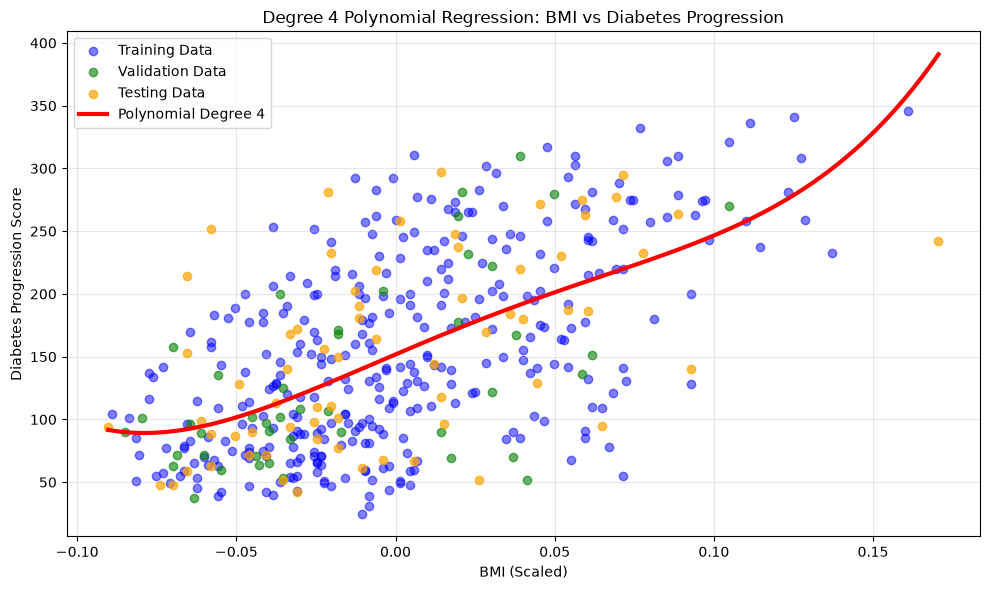

In [17]:
# Step 10: Visualize the best polynomial regression model

# Generate BMI values covering all three datasets
bmi_range = np.linspace(
    X["bmi"].min(),
    X["bmi"].max(),
    300
)

# Convert into a DataFrame for prediction
bmi_curve = pd.DataFrame({"bmi": bmi_range})

# Predict using the selected model
progression_curve = best_model.predict(bmi_curve)

# Create graph
plt.figure(figsize=(10, 6))

# Training data
plt.scatter(
    X_train_bmi["bmi"],
    y_train,
    color="blue",
    alpha=0.5,
    label="Training Data"
)

# Validation data
plt.scatter(
    X_val_bmi["bmi"],
    y_val,
    color="green",
    alpha=0.6,
    label="Validation Data"
)

# Testing data
plt.scatter(
    X_test_bmi["bmi"],
    y_test,
    color="orange",
    alpha=0.7,
    label="Testing Data"
)

# Plot best-fit polynomial curve
plt.plot(
    bmi_range,
    progression_curve,
    color="red",
    linewidth=3,
    label=f"Polynomial Degree {best_degree}"
)

plt.title("Degree 4 Polynomial Regression: BMI vs Diabetes Progression")
plt.xlabel("BMI (Scaled)")
plt.ylabel("Diabetes Progression Score")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Step 10: Visualization Analysis

The Degree 4 polynomial regression curve shows an overall
positive relationship between BMI and diabetes progression.

However, many observations are widely scattered around
the fitted curve, indicating substantial prediction errors.

The curve also rises sharply at higher BMI values,
suggesting that predictions in sparsely populated regions
may be unreliable.

These findings highlight the limitations of using BMI
alone to predict diabetes progression.

### Step 11: Equation of the Best Polynomial Model

**Objective:** Extract the learned coefficients of the
selected Degree 4 polynomial regression model and
construct its mathematical equation.

The equation represents the relationship between
scaled BMI and predicted diabetes progression.

Coefficients will be displayed to two decimal places.

In [18]:
# Step 11: Extract the equation of the best model

# Access the polynomial and regression components
poly = best_model.named_steps["poly"]
linear = best_model.named_steps["linear"]

# Get polynomial feature names
feature_names = poly.get_feature_names_out(["bmi"])

# Get the learned coefficients
coefficients = linear.coef_

# Display each coefficient
print("Polynomial Model Coefficients:")

for feature, coefficient in zip(feature_names, coefficients):
    print(f"{feature}: {coefficient:.2f}")

# Construct the polynomial equation
equation = f"y = {coefficients[0]:.2f}"

for power, coefficient in enumerate(coefficients[1:], start=1):
    sign = "+" if coefficient >= 0 else "-"
    term = "BMI" if power == 1 else f"BMI^{power}"

    equation += f" {sign} {abs(coefficient):.2f} * {term}"

print("\nBest Model Equation:")
print(equation)

Polynomial Model Coefficients:
1: 151.83
bmi: 1081.79
bmi^2: -884.83
bmi^3: -34140.54
bmi^4: 295126.62

Best Model Equation:
y = 151.83 + 1081.79 * BMI - 884.83 * BMI^2 - 34140.54 * BMI^3 + 295126.62 * BMI^4


#### Step 11: Model Equation Analysis

The selected Degree 4 Polynomial Regression model has
five learned coefficients, including the intercept.

The fitted equation is:

ŷ = 151.83 + 1081.79x - 884.83x²
    - 34140.54x³ + 295126.62x⁴

where x represents scaled BMI and ŷ represents
predicted diabetes progression.

The model includes nonlinear polynomial terms,
allowing it to represent a curved relationship
between BMI and diabetes progression.

The coefficients are rounded to two decimal places.

### Step 12: Predict Diabetes Progression for a Selected BMI

**Objective:** Use the selected Degree 4 polynomial
regression model to predict diabetes progression
for a chosen scaled BMI value of 0.05.

The prediction is generated using model.predict()
without retraining the model.

In [19]:
# Step 12: Predict diabetes progression for a selected BMI

# Choose a scaled BMI value
selected_bmi = 0.05

# Create a DataFrame for prediction
bmi_input = pd.DataFrame({
    "bmi": [selected_bmi]
})

# Predict using our trained Degree 4 model
predicted_progression = best_model.predict(bmi_input)

# Display the prediction
print("Selected BMI (Scaled):", selected_bmi)
print(f"Predicted Diabetes Progression: {predicted_progression[0]:.2f}")

Selected BMI (Scaled): 0.05
Predicted Diabetes Progression: 201.29


#### Step 12: Prediction Result

For a selected scaled BMI value of 0.05, the Degree 4
Polynomial Regression model predicts a diabetes
progression score of 201.29.

The prediction demonstrates how the trained model
estimates disease progression from an individual BMI
value. However, the prediction is an estimate and
does not account for other patient characteristics.

### Step 13: Trainable Parameters Analysis

**Objective:** Determine the number of trainable parameters
in each polynomial regression model (degrees 0 to 5).

Trainable parameters are the coefficients learned during
model training.

The PolynomialFeatures method generates polynomial terms,
while LinearRegression estimates their coefficients.

The number of parameters is determined using
get_feature_names_out() and the learned coefficients.

In [20]:
# Step 13: Count trainable parameters for each model

parameter_results = []

for degree, model in polynomial_models.items():

    # Access polynomial transformation
    poly = model.named_steps["poly"]

    # Access trained regression model
    linear = model.named_steps["linear"]

    # Get polynomial feature names
    feature_names = poly.get_feature_names_out(["bmi"])

    # Count trainable coefficients
    parameter_count = len(linear.coef_)

    parameter_results.append({
        "Degree": degree,
        "Polynomial Features": ", ".join(feature_names),
        "Trainable Parameters": parameter_count
    })

# Convert results into a DataFrame
parameter_df = pd.DataFrame(parameter_results)

display(parameter_df)

,Degree,Polynomial Features,Trainable Parameters
0,0,1,1
1,1,"1, bmi",2
2,2,"1, bmi, bmi^2",3
3,3,"1, bmi, bmi^2, bmi^3",4
4,4,"1, bmi, bmi^2, bmi^3, bmi^4",5
5,5,"1, bmi, bmi^2, bmi^3, bmi^4, bmi^5",6


#### Step 13: Parameter Analysis

The number of trainable parameters increases with
the polynomial degree.

- Degree 0 contains 1 parameter (constant).
- Degree 1 contains 2 parameters.
- Degree 2 contains 3 parameters.
- Degree 3 contains 4 parameters.
- Degree 4 contains 5 parameters.
- Degree 5 contains 6 parameters.

The number of parameters equals the polynomial degree
plus one, including the constant term.

Higher-degree models have greater flexibility but may
also increase the risk of overfitting.

The selected Degree 4 model contains five trainable
parameters and achieved the best validation performance.

### Step 14: Final Model Analysis and Conclusion

#### Step 14.1: Prediction Error Analysis

**Objective:** Investigate where the selected Degree 4
polynomial regression model produces inaccurate predictions.

The analysis compares actual and predicted progression
scores and examines residual errors across BMI values.

This helps identify model weaknesses and supports a
more meaningful discussion of model limitations.

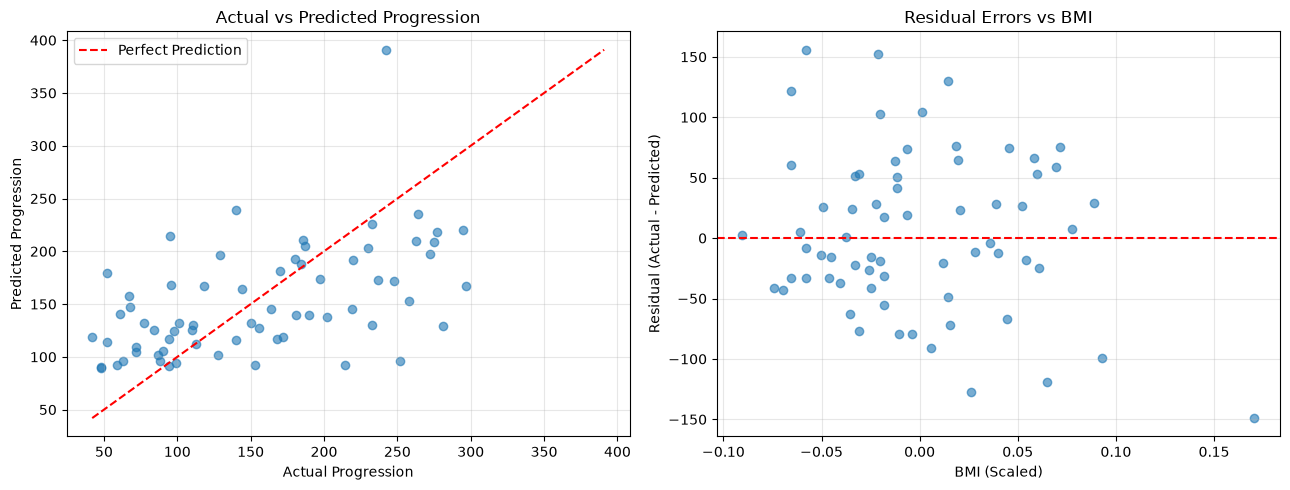

Five Largest Prediction Errors:


,BMI,Actual,Predicted,Residual,Absolute Error
9,-0.06,252.0,96.15,155.85,155.85
17,-0.02,281.0,128.79,152.21,152.21
66,0.17,242.0,390.95,-148.95,148.95
59,0.01,297.0,167.01,129.99,129.99
18,0.03,52.0,179.02,-127.02,127.02


In [21]:
# Step 14.1: Analyze prediction errors

# Create DataFrame containing test predictions
test_diagnostics = pd.DataFrame({
    "BMI": X_test_bmi["bmi"].to_numpy(),
    "Actual": y_test.to_numpy(),
    "Predicted": y_test_pred
})

# Calculate prediction errors
test_diagnostics["Residual"] = (
    test_diagnostics["Actual"] - test_diagnostics["Predicted"]
)

test_diagnostics["Absolute Error"] = (
    test_diagnostics["Residual"].abs()
)

# Create two diagnostic plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot 1: Actual vs Predicted
axes[0].scatter(
    test_diagnostics["Actual"],
    test_diagnostics["Predicted"],
    alpha=0.6
)

# Reference line for perfect predictions
lower = min(
    test_diagnostics["Actual"].min(),
    test_diagnostics["Predicted"].min()
)

upper = max(
    test_diagnostics["Actual"].max(),
    test_diagnostics["Predicted"].max()
)

axes[0].plot(
    [lower, upper],
    [lower, upper],
    "r--",
    label="Perfect Prediction"
)

axes[0].set_title("Actual vs Predicted Progression")
axes[0].set_xlabel("Actual Progression")
axes[0].set_ylabel("Predicted Progression")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot 2: Residuals vs BMI
axes[1].scatter(
    test_diagnostics["BMI"],
    test_diagnostics["Residual"],
    alpha=0.6
)

axes[1].axhline(0, color="red", linestyle="--")

axes[1].set_title("Residual Errors vs BMI")
axes[1].set_xlabel("BMI (Scaled)")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Display the five largest prediction errors
print("Five Largest Prediction Errors:")

display(
    test_diagnostics.nlargest(
        5, "Absolute Error"
    ).round(2)
)

#### Step 14.2: Final Conclusion and Model Limitations

##### Model Performance Summary

Six univariate polynomial regression models, ranging
from degree 0 to degree 5, were developed using BMI
to predict diabetes disease progression.

Degree 4 was selected based on its validation performance.

The selected model achieved the following test results:

- R²: 0.2401
- MAE: 52.3054
- MAPE: 43.30%

The test R² indicates that the model explains approximately
24.01% of the variation in the test target values.

The MAE indicates an average absolute prediction error
of approximately 52.31 progression-score units.

##### Prediction Error Analysis

The actual-versus-predicted plot shows considerable
deviation from the perfect prediction line.

The model produces both overestimation and underestimation
errors, particularly for patients with unusual progression
scores.

Examples from the test dataset include:

- Actual 252, Predicted 96.15: Underestimated by 155.85.
- Actual 281, Predicted 128.79: Underestimated by 152.21.
- Actual 242, Predicted 390.95: Overestimated by 148.95.

The residual plot also shows substantial errors across
different BMI values.

These results demonstrate that patients with similar BMI
values can have very different progression scores.

##### Overfitting and Generalization

The selected model achieved a validation R² of 0.3408,
which decreased to 0.2401 on the test dataset.

Test MAE also increased from 46.09 to 52.31.

This suggests weaker generalization to unseen data.

Although the training and validation R² values were
relatively close, the difference in test performance
highlights uncertainty in model generalization.

The sharp increase in the fitted curve at high BMI values
also suggests sensitivity to polynomial complexity.

##### Model Limitations

1. Single Feature:
   The model uses only BMI and ignores other potentially
   important variables such as blood pressure and serum
   measurements.

2. Prediction Accuracy:
   The relatively low R² and high prediction errors
   indicate limited predictive performance.

3. Extreme Values:
   The model can produce unrealistic progression estimates,
   especially near the boundaries of the observed BMI range.

4. Dataset Size:
   The dataset contains only 442 observations, and the
   test set contains 67 observations. Performance estimates
   may vary with different data splits.

5. Clinical Applicability:
   The dataset is intended for educational modeling.
   The model is not clinically validated and should not
   be used independently for medical screening decisions.

##### Connections to Previous Workshops

The Classification Performance Metrics workshop emphasized
the importance of evaluating models using appropriate
metrics rather than relying on a single score.

Similarly, regression models require multiple metrics
such as R², MAE, and MAPE to evaluate predictive performance.

The K-Nearest Neighbors workshop demonstrated how model
complexity and hyperparameter choices influence
generalization. Similar considerations apply when selecting
the polynomial degree.

The Logistic Regression workshop illustrated the distinction
between classification and regression. Logistic Regression
predicts classes or class probabilities, whereas the current
polynomial model predicts continuous progression scores.

##### Final Conclusion

Degree 4 achieved the best validation performance among
the six polynomial models, but its test results indicate
substantial remaining prediction error.

BMI is positively associated with diabetes progression,
but BMI alone is insufficient for reliable prediction.

Future improvements could include additional patient
features, alternative regression algorithms, and
cross-validation for more robust model selection.

These improvements will be investigated through
multivariate modeling in Part 3.

## Part 3: Multivariate Model Development

### Step 15: Feature Selection and Data Preparation

**Objective:** Select relevant input features for
multivariate modeling using training data only.

Pearson correlations are calculated between the training
features and the training target.

The three strongest positively correlated features and
the strongest negatively correlated feature are selected.

Feature selection is restricted to training observations
to reduce information leakage from validation and test data.

The selected features are then extracted from the existing
training, validation, and test partitions.

Using the same selected features across models supports
consistent comparisons.

In [22]:
# Step 15: Training-Based Feature Selection

# Calculate correlations using training data only
train_data = X_train.copy()
train_data["target"] = y_train

train_correlations = (
    train_data.corr()["target"]
    .drop("target")
)

print("Training Feature Correlations:")
display(
    train_correlations
    .sort_values(key=abs, ascending=False)
    .round(3)
)

# Select the three strongest positive relationships
positive_features = (
    train_correlations[train_correlations > 0]
    .nlargest(3)
    .index.tolist()
)

# Select the strongest negative relationship
negative_features = (
    train_correlations[train_correlations < 0]
    .nsmallest(1)
    .index.tolist()
)

# Preserve the original dataset's feature order
selected_set = set(positive_features + negative_features)

selected_features = [
    col for col in X_train.columns
    if col in selected_set
]

# Prepare multivariate datasets
X_train_multi = X_train[selected_features]
X_val_multi = X_val[selected_features]
X_test_multi = X_test[selected_features]

print("\nSelected Features:", selected_features)

print("\nTraining shape:", X_train_multi.shape)
print("Validation shape:", X_val_multi.shape)
print("Testing shape:", X_test_multi.shape)

display(X_train_multi.head())

Training Feature Correlations:


bmi    0.591
s5     0.534
bp     0.442
s4     0.424
s3    -0.397
s6     0.371
age    0.198
s1     0.182
s2     0.147
sex    0.014
Name: target, dtype: float64


Selected Features: ['bmi', 'bp', 's3', 's5']

Training shape: (331, 4)
Validation shape: (44, 4)
Testing shape: (67, 4)


,bmi,bp,s3,s5
16,0.042296,0.049415,0.074412,0.052277
408,-0.050396,0.107944,-0.017629,0.058038
432,0.055229,-0.005670,-0.002903,0.055686
316,0.014272,0.001215,-0.032356,0.074966
3,-0.011595,-0.036656,-0.036038,0.022688


### Step 16: Multivariate Polynomial Regression

#### Step 16.1: Training Polynomial Models

**Objective:** Develop two multivariate polynomial regression
models using polynomial degrees 2 and 3.

The selected input features are BMI, BP, S3, and S5.

PolynomialFeatures generates polynomial and interaction
terms, while LinearRegression learns their coefficients.

The models will be trained using the training dataset
and subsequently compared using validation performance.

In [23]:
# Step 16.1: Train Multivariate Polynomial Regression Models

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

# Dictionary to store trained models
multi_poly_models = {}

# Train Degree 2 and Degree 3 models
for degree in [2, 3]:

    # Create polynomial regression pipeline
    model = Pipeline([
        ("poly", PolynomialFeatures(
            degree=degree,
            include_bias=True
        )),
        ("linear", LinearRegression(fit_intercept=False))
    ])

    # Train using four input features
    model.fit(X_train_multi, y_train)

    # Store trained model
    multi_poly_models[degree] = model

    # Count polynomial features
    feature_names = model.named_steps[
        "poly"
    ].get_feature_names_out(selected_features)

    print(f"Polynomial Degree {degree}: Training Completed")
    print(f"Number of Polynomial Features: {len(feature_names)}")
    print("-----------------------------------")

print("\nBoth multivariate polynomial models trained successfully.")

Polynomial Degree 2: Training Completed
Number of Polynomial Features: 15
-----------------------------------
Polynomial Degree 3: Training Completed
Number of Polynomial Features: 35
-----------------------------------

Both multivariate polynomial models trained successfully.


#### Step 16.2: Polynomial Model Evaluation

**Objective:** Evaluate Degree 2 and Degree 3 multivariate
polynomial regression models using training and validation data.

Model performance is measured using R², MAE, and MAPE.

The evaluation helps determine whether increasing polynomial
complexity improves predictive performance and whether
either model shows signs of overfitting.

The test dataset remains reserved for final evaluation.

In [24]:
# Step 16.2: Evaluate Multivariate Polynomial Models

multi_poly_results = []

# Evaluate Degree 2 and Degree 3 models
for degree, model in multi_poly_models.items():

    # Predict training and validation values
    y_train_pred = model.predict(X_train_multi)
    y_val_pred = model.predict(X_val_multi)

    # Calculate training metrics
    train_r2 = r2_score(y_train, y_train_pred)
    train_mae = mean_absolute_error(y_train, y_train_pred)
    train_mape = mean_absolute_percentage_error(
        y_train, y_train_pred
    ) * 100

    # Calculate validation metrics
    val_r2 = r2_score(y_val, y_val_pred)
    val_mae = mean_absolute_error(y_val, y_val_pred)
    val_mape = mean_absolute_percentage_error(
        y_val, y_val_pred
    ) * 100

    # Store evaluation results
    multi_poly_results.append({
        "Model": f"Polynomial Degree {degree}",
        "Train R2": train_r2,
        "Validation R2": val_r2,
        "Train MAE": train_mae,
        "Validation MAE": val_mae,
        "Train MAPE (%)": train_mape,
        "Validation MAPE (%)": val_mape
    })

# Convert results into a DataFrame
multi_poly_results_df = pd.DataFrame(multi_poly_results)

# Display results
display(multi_poly_results_df.round(3))

,Model,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
0,Polynomial Degree 2,0.51,0.389,44.972,41.858,39.540,39.544
1,Polynomial Degree 3,0.53,0.419,43.680,42.728,38.123,41.759


### Step 17: Decision Tree Regression

#### Step 17.1: Training Decision Tree Models

**Objective:** Train two Decision Tree Regression models
using the selected multivariate features.

Two maximum depths are tested:
- Model 1: max_depth = 3
- Model 2: max_depth = 5

Decision Trees predict continuous target values by
splitting data into groups based on feature values.

Comparing different tree depths helps examine the
relationship between model complexity, prediction
performance, and potential overfitting.

In [25]:
# Step 17.1: Train Decision Tree Regression Models

from sklearn.tree import DecisionTreeRegressor

# Dictionary to store trained decision tree models
decision_tree_models = {}

# Train two trees with different maximum depths
for depth in [3, 5]:

    # Create Decision Tree Regressor
    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    # Train using four selected features
    model.fit(X_train_multi, y_train)

    # Store trained model
    decision_tree_models[depth] = model

    print(f"Decision Tree max_depth={depth}: Training Completed")

print("\nBoth Decision Tree models trained successfully.")

Decision Tree max_depth=3: Training Completed
Decision Tree max_depth=5: Training Completed

Both Decision Tree models trained successfully.


#### Step 17.2: Decision Tree Model Evaluation

**Objective:** Evaluate and compare two Decision Tree
Regression models with maximum depths of 3 and 5.

Both models are evaluated using training and validation
datasets with R², MAE, and MAPE metrics.

The comparison helps determine whether increasing tree
depth improves predictive performance or introduces
overfitting.

The test dataset remains reserved for final evaluation.

In [26]:
# Step 17.2: Evaluate Decision Tree Regression Models

decision_tree_results = []

# Evaluate both decision tree models
for depth, model in decision_tree_models.items():

    # Predict using training and validation data
    y_train_pred = model.predict(X_train_multi)
    y_val_pred = model.predict(X_val_multi)

    # Calculate training metrics
    train_r2 = r2_score(y_train, y_train_pred)
    train_mae = mean_absolute_error(y_train, y_train_pred)
    train_mape = mean_absolute_percentage_error(
        y_train, y_train_pred
    ) * 100

    # Calculate validation metrics
    val_r2 = r2_score(y_val, y_val_pred)
    val_mae = mean_absolute_error(y_val, y_val_pred)
    val_mape = mean_absolute_percentage_error(
        y_val, y_val_pred
    ) * 100

    # Store evaluation results
    decision_tree_results.append({
        "Model": f"Decision Tree Depth {depth}",
        "Train R2": train_r2,
        "Validation R2": val_r2,
        "Train MAE": train_mae,
        "Validation MAE": val_mae,
        "Train MAPE (%)": train_mape,
        "Validation MAPE (%)": val_mape
    })

# Convert results into a DataFrame
decision_tree_results_df = pd.DataFrame(decision_tree_results)

# Display full comparison
display(decision_tree_results_df.round(3))

,Model,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
0,Decision Tree Depth 3,0.501,0.363,45.079,42.531,39.214,42.779
1,Decision Tree Depth 5,0.653,0.280,35.537,42.971,31.353,41.872


### Step 18: K-Nearest Neighbors (kNN) Regression

#### Step 18.1: Training kNN Models

**Objective:** Develop two K-Nearest Neighbors regression
models using the selected multivariate features.

Two configurations are evaluated:
- Model 1: n_neighbors = 5
- Model 2: n_neighbors = 10

kNN Regression predicts a continuous target value based
on the average target values of neighboring observations.

The dataset's input features are already scaled, which
is important because kNN calculates distances between
observations.

Both models will be trained using the training dataset
and compared using validation performance.

In [27]:
# Step 18.1: Train kNN Regression Models

from sklearn.neighbors import KNeighborsRegressor

# Dictionary to store trained kNN models
knn_models = {}

# Train kNN models with K = 5 and K = 10
for k in [5, 10]:

    # Create kNN Regression model
    model = KNeighborsRegressor(
        n_neighbors=k,
        weights="uniform"
    )

    # Fit model using four selected features
    model.fit(X_train_multi, y_train)

    # Store trained model
    knn_models[k] = model

    print(f"kNN Regression K={k}: Training Completed")

print("\nBoth kNN Regression models trained successfully.")

kNN Regression K=5: Training Completed
kNN Regression K=10: Training Completed

Both kNN Regression models trained successfully.


#### Step 18.2: kNN Regression Model Evaluation

**Objective:** Evaluate and compare two kNN regression
models using 5 and 10 nearest neighbors.

Both models are evaluated using training and validation
datasets with R², MAE, and MAPE metrics.

The comparison helps determine how the number of
neighbors affects prediction accuracy, model complexity,
and generalization performance.

The test dataset remains reserved for final evaluation.

In [28]:
# Step 18.2: Evaluate kNN Regression Models

knn_results = []

# Evaluate both kNN models
for k, model in knn_models.items():

    # Predict using training and validation data
    y_train_pred = model.predict(X_train_multi)
    y_val_pred = model.predict(X_val_multi)

    # Calculate training metrics
    train_r2 = r2_score(y_train, y_train_pred)
    train_mae = mean_absolute_error(y_train, y_train_pred)
    train_mape = mean_absolute_percentage_error(
        y_train, y_train_pred
    ) * 100

    # Calculate validation metrics
    val_r2 = r2_score(y_val, y_val_pred)
    val_mae = mean_absolute_error(y_val, y_val_pred)
    val_mape = mean_absolute_percentage_error(
        y_val, y_val_pred
    ) * 100

    # Store evaluation results
    knn_results.append({
        "Model": f"kNN Regression K={k}",
        "Train R2": train_r2,
        "Validation R2": val_r2,
        "Train MAE": train_mae,
        "Validation MAE": val_mae,
        "Train MAPE (%)": train_mape,
        "Validation MAPE (%)": val_mape
    })

# Convert results into a DataFrame
knn_results_df = pd.DataFrame(knn_results)

# Display full results
display(knn_results_df.round(3))

,Model,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
0,kNN Regression K=5,0.552,0.284,41.796,47.427,36.834,46.252
1,kNN Regression K=10,0.526,0.369,43.309,43.059,38.697,42.167


### Step 19: Logistic Regression Classification

#### Step 19.1: Target Transformation

**Objective:** Convert the continuous diabetes progression
target into binary categories for Logistic Regression.

The median progression score from the training dataset
is used as the classification threshold.

- Class 0: Progression at or below the training median.
- Class 1: Progression above the training median.

The threshold is calculated using training data only
to avoid information leakage.

These categories are created for educational model
comparison and do not represent clinical risk thresholds.

In [29]:
# Step 19.1: Prepare Classification Target

# Calculate threshold using training data only
progression_threshold = y_train.median()

# Convert numerical targets into binary classes
y_train_class = (y_train > progression_threshold).astype(int)
y_val_class = (y_val > progression_threshold).astype(int)

# Display the threshold
print("Progression Threshold:", progression_threshold)

# Display class distribution
print("\nTraining Class Distribution:")
print(y_train_class.value_counts().sort_index())

print("\nValidation Class Distribution:")
print(y_val_class.value_counts().sort_index())

Progression Threshold: 142.0

Training Class Distribution:
target
0    167
1    164
Name: count, dtype: int64

Validation Class Distribution:
target
0    29
1    15
Name: count, dtype: int64


#### Step 19.2: Training Logistic Regression Models

**Objective:** Train two Logistic Regression classification
models using four selected patient features.

The models use different regularization strengths:

- Model 1: C = 0.1 (stronger regularization)
- Model 2: C = 10 (weaker regularization)

StandardScaler is included in each pipeline to standardize
the features using training data only.

The models predict whether diabetes progression is above
or at/below the training median threshold of 142.

The impact of regularization will be evaluated using
classification metrics on training and validation data.

In [30]:
# Step 19.2: Train Logistic Regression Models

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Dictionary to store trained models
logistic_models = {}

# Train two models with different regularization strengths
for c_value in [0.1, 10]:

    # Create Logistic Regression pipeline
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            C=c_value,
            max_iter=1000
        ))
    ])

    # Train using four selected features
    model.fit(X_train_multi, y_train_class)

    # Store trained model
    logistic_models[c_value] = model

    print(f"Logistic Regression C={c_value}: Training Completed")

print("\nBoth Logistic Regression models trained successfully.")

Logistic Regression C=0.1: Training Completed
Logistic Regression C=10: Training Completed

Both Logistic Regression models trained successfully.


#### Step 19.3: Logistic Regression Model Evaluation

**Objective:** Evaluate and compare the two Logistic Regression
models using training and validation datasets.

Since Logistic Regression predicts categorical outcomes,
classification metrics are used instead of regression metrics.

The evaluation includes:
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

The positive class (Class 1) represents progression scores
above the training median of 142.

The models will be compared using validation performance
to assess generalization and the effect of regularization.

These categories are educational and do not represent
clinically validated risk thresholds.

In [31]:
# Step 19.3: Evaluate Logistic Regression Models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Store evaluation results
logistic_results = []

# Evaluate both Logistic Regression models
for c_value, model in logistic_models.items():

    # Predict training and validation classes
    y_train_pred = model.predict(X_train_multi)
    y_val_pred = model.predict(X_val_multi)

    # Calculate training metrics
    train_accuracy = accuracy_score(y_train_class, y_train_pred)
    train_precision = precision_score(
        y_train_class, y_train_pred, zero_division=0
    )
    train_recall = recall_score(
        y_train_class, y_train_pred, zero_division=0
    )
    train_f1 = f1_score(
        y_train_class, y_train_pred, zero_division=0
    )

    # Calculate validation metrics
    val_accuracy = accuracy_score(y_val_class, y_val_pred)
    val_precision = precision_score(
        y_val_class, y_val_pred, zero_division=0
    )
    val_recall = recall_score(
        y_val_class, y_val_pred, zero_division=0
    )
    val_f1 = f1_score(
        y_val_class, y_val_pred, zero_division=0
    )

    # Store evaluation results
    logistic_results.append({
        "Model": f"Logistic Regression C={c_value}",
        "Train Accuracy": train_accuracy,
        "Validation Accuracy": val_accuracy,
        "Train Precision": train_precision,
        "Validation Precision": val_precision,
        "Train Recall": train_recall,
        "Validation Recall": val_recall,
        "Train F1": train_f1,
        "Validation F1": val_f1
    })

    # Display validation confusion matrix
    print(f"\nConfusion Matrix for C={c_value}:")
    print(confusion_matrix(y_val_class, y_val_pred))

# Convert results into DataFrame
logistic_results_df = pd.DataFrame(logistic_results)

# Display comparison results
print("\nLogistic Regression Model Comparison:")
display(logistic_results_df.round(3))


Confusion Matrix for C=0.1:
[[25  4]
 [ 3 12]]

Confusion Matrix for C=10:
[[25  4]
 [ 3 12]]

Logistic Regression Model Comparison:


,Model,Train Accuracy,Validation Accuracy,Train Precision,Validation Precision,Train Recall,Validation Recall,Train F1,Validation F1
0,Logistic Regression C=0.1,0.74,0.841,0.744,0.75,0.726,0.8,0.735,0.774
1,Logistic Regression C=10,0.74,0.841,0.744,0.75,0.726,0.8,0.735,0.774


### Step 20: Model Comparison and Selection

#### Step 20.1: Regression Model Comparison

**Objective:** Compare the performance of multivariate
Polynomial Regression, Decision Tree Regression, and
kNN Regression models.

The selected BMI-only Degree 4 model from Part 2 is
included as a reference.

The comparison uses training and validation R²,
MAE, and MAPE.

Validation MAE is used as the primary criterion for
selecting the best regression model, while R² and MAPE
provide supporting information.

Logistic Regression models are evaluated separately
because they predict categorical outcomes.

In [32]:
# Step 20.1: Combined Regression Model Comparison

# Include the best BMI-only model from Part 2
bmi_baseline = results_df[
    results_df["Degree"] == 4
].copy()

bmi_baseline["Model"] = "BMI Polynomial Degree 4"

# Combine all regression results
regression_comparison = pd.concat(
    [
        bmi_baseline,
        multi_poly_results_df,
        decision_tree_results_df,
        knn_results_df
    ],
    ignore_index=True
)

# Select comparison columns
comparison_columns = [
    "Model",
    "Train R2",
    "Validation R2",
    "Train MAE",
    "Validation MAE",
    "Train MAPE (%)",
    "Validation MAPE (%)"
]

regression_comparison = regression_comparison[
    comparison_columns
]

# Sort models by lowest validation MAE
regression_comparison = regression_comparison.sort_values(
    by="Validation MAE",
    ascending=True
)

# Display results
print("Combined Regression Model Comparison:")
display(regression_comparison.round(3))

Combined Regression Model Comparison:


,Model,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
1,Polynomial Degree 2,0.510,0.389,44.972,41.858,39.540,39.544
3,Decision Tree Depth 3,0.501,0.363,45.079,42.531,39.214,42.779
2,Polynomial Degree 3,0.530,0.419,43.680,42.728,38.123,41.759
4,Decision Tree Depth 5,0.653,0.280,35.537,42.971,31.353,41.872
6,kNN Regression K=10,0.526,0.369,43.309,43.059,38.697,42.167
0,BMI Polynomial Degree 4,0.353,0.341,52.093,46.090,48.053,46.050
5,kNN Regression K=5,0.552,0.284,41.796,47.427,36.834,46.252


#### Step 20.2: Final Regression Model Test Evaluation

**Objective:** Evaluate the selected multivariate
Polynomial Regression Degree 2 model using the
previously reserved test dataset.

Degree 2 was selected based on its lowest validation
MAE among the regression models.

The test evaluation uses R², MAE, and MAPE to
measure predictive performance on unseen observations.

The model is not retrained or modified using test data.

In [33]:
# Step 20.2: Evaluate the selected multivariate model

# Retrieve the selected Degree 2 model
best_multi_model = multi_poly_models[2]

# Predict on the test dataset
y_test_pred_multi = best_multi_model.predict(X_test_multi)

# Calculate test metrics
multi_test_r2 = r2_score(y_test, y_test_pred_multi)

multi_test_mae = mean_absolute_error(
    y_test, y_test_pred_multi
)

multi_test_mape = mean_absolute_percentage_error(
    y_test, y_test_pred_multi
) * 100

# Display results
print("Selected Model: Multivariate Polynomial Degree 2")

print("\nTest Set Performance")
print("---------------------------")
print(f"R-Squared (R²): {multi_test_r2:.4f}")
print(f"MAE: {multi_test_mae:.4f}")
print(f"MAPE: {multi_test_mape:.2f}%")

Selected Model: Multivariate Polynomial Degree 2

Test Set Performance
---------------------------
R-Squared (R²): 0.5105
MAE: 43.3109
MAPE: 36.33%


##### Test Performance Analysis

The selected Multivariate Polynomial Regression Degree 2
model achieved the following test results:

- R²: 0.5105
- MAE: 43.3109
- MAPE: 36.33%

Compared with the BMI-only Degree 4 model from Part 2,
the multivariate model improved test R² from 0.2401
to 0.5105.

Test MAE decreased from 52.31 to 43.31, representing
approximately a 17.2% reduction in average absolute error.

These findings suggest that combining BMI, BP, S3,
and S5 provides more useful predictive information
than BMI alone.

However, considerable prediction error remains,
indicating that the model has limitations.

#### Step 20.3: Individual Patient Prediction

**Objective:** Demonstrate how the selected multivariate
model predicts diabetes progression using four features.

A patient observation from the test dataset is selected,
and its predicted progression score is compared with
the actual value.

The model is used only for prediction and is not retrained.

In [34]:
# Step 20.3: Individual patient prediction

# Select the first patient from the test dataset
sample_patient = X_test_multi.iloc[[0]]

# Display the patient's feature values
print("Selected Patient Features:")
display(sample_patient)

# Predict using our best multivariate model
sample_prediction = best_multi_model.predict(sample_patient)

# Retrieve actual progression score
actual_progression = y_test.iloc[0]

# Display prediction and actual value
print(f"Predicted Progression: {sample_prediction[0]:.2f}")
print(f"Actual Progression: {actual_progression:.2f}")

# Calculate absolute prediction error
prediction_error = abs(actual_progression - sample_prediction[0])

print(f"Absolute Error: {prediction_error:.2f}")

Selected Patient Features:


,bmi,bp,s3,s5
176,0.019662,0.039087,0.008142,-0.003301


Predicted Progression: 165.32
Actual Progression: 237.00
Absolute Error: 71.68


#### Step 20.4: Trainable Parameters and Model Equation

**Objective:** Examine the polynomial features and learned
coefficients of the selected multivariate Degree 2 model.

The model uses four input features: BMI, BP, S3, and S5.

PolynomialFeatures generates individual, squared, and
interaction terms, resulting in 15 trainable coefficients,
including the constant term.

The learned coefficients are extracted to understand
the structure of the fitted polynomial equation.

In [35]:
# Step 20.4: Extract Multivariate Polynomial Coefficients

# Access the polynomial transformer
poly = best_multi_model.named_steps["poly"]

# Access the trained linear regression model
linear = best_multi_model.named_steps["linear"]

# Get polynomial feature names
feature_names = poly.get_feature_names_out(selected_features)

# Get learned coefficients
coefficients = linear.coef_

# Create a coefficient table
coefficient_df = pd.DataFrame({
    "Polynomial Term": feature_names,
    "Coefficient": coefficients
})

print("Selected Model: Multivariate Polynomial Degree 2")

print("\nNumber of Trainable Parameters:", len(coefficients))

print("\nLearned Polynomial Coefficients:")
display(coefficient_df.round(2))

# Construct the polynomial equation
equation = f"y = {coefficients[0]:.2f}"

for term, coefficient in zip(feature_names[1:], coefficients[1:]):

    sign = "+" if coefficient >= 0 else "-"

    equation += f" {sign} {abs(coefficient):.2f} * ({term})"

print("\nBest Multivariate Model Equation:")
print(equation)

Selected Model: Multivariate Polynomial Degree 2

Number of Trainable Parameters: 15

Learned Polynomial Coefficients:


,Polynomial Term,Coefficient
0,1,145.32
1,bmi,483.91
2,bp,315.41
3,s3,-331.64
4,s5,420.09
5,bmi^2,1807.90
6,bmi bp,1941.76
7,bmi s3,-1400.54
8,bmi s5,-627.88
9,bp^2,40.38



Best Multivariate Model Equation:
y = 145.32 + 483.91 * (bmi) + 315.41 * (bp) - 331.64 * (s3) + 420.09 * (s5) + 1807.90 * (bmi^2) + 1941.76 * (bmi bp) - 1400.54 * (bmi s3) - 627.88 * (bmi s5) + 40.38 * (bp^2) + 1244.52 * (bp s3) + 1882.99 * (bp s5) + 1077.84 * (s3^2) + 1517.63 * (s3 s5) - 886.29 * (s5^2)


#### Step 20.5: Model Structure and Complexity Analysis

**Objective:** Compare the learned structures and complexity
of the different machine learning models.

Polynomial and Logistic Regression use learned coefficients,
Decision Trees use hierarchical splitting rules, and kNN
uses stored training observations to make predictions.

Examining these differences helps explain how model
complexity may influence generalization and overfitting.

In [36]:
# Step 20.5: Compare Model Structures

model_structures = []

# Polynomial Regression
for degree, model in multi_poly_models.items():

    coefficient_count = len(
        model.named_steps["linear"].coef_
    )

    model_structures.append({
        "Model": f"Polynomial Degree {degree}",
        "Structure": "Polynomial coefficients",
        "Details": f"{coefficient_count} coefficients"
    })

# Decision Tree Regression
for depth, model in decision_tree_models.items():

    model_structures.append({
        "Model": f"Decision Tree Depth {depth}",
        "Structure": "Tree splits and leaves",
        "Details": (
            f"Depth: {model.get_depth()}, "
            f"Leaves: {model.get_n_leaves()}, "
            f"Nodes: {model.tree_.node_count}"
        )
    })

# kNN Regression
for k, model in knn_models.items():

    model_structures.append({
        "Model": f"kNN K={k}",
        "Structure": "Stored training observations",
        "Details": f"K={k}, Samples={model.n_samples_fit_}"
    })

# Logistic Regression
for c_value, model in logistic_models.items():

    logistic = model.named_steps["logistic"]

    coefficient_count = (
        logistic.coef_.size + logistic.intercept_.size
    )

    model_structures.append({
        "Model": f"Logistic Regression C={c_value}",
        "Structure": "Learned coefficients",
        "Details": f"{coefficient_count} coefficients"
    })

# Display comparison
structure_df = pd.DataFrame(model_structures)

display(structure_df)

,Model,Structure,Details
0,Polynomial Degree 2,Polynomial coefficients,15 coefficients
1,Polynomial Degree 3,Polynomial coefficients,35 coefficients
2,Decision Tree Depth 3,Tree splits and leaves,"Depth: 3, Leaves: 8, Nodes: 15"
3,Decision Tree Depth 5,Tree splits and leaves,"Depth: 5, Leaves: 32, Nodes: 63"
4,kNN K=5,Stored training observations,"K=5, Samples=331"
5,kNN K=10,Stored training observations,"K=10, Samples=331"
6,Logistic Regression C=0.1,Learned coefficients,5 coefficients
7,Logistic Regression C=10,Learned coefficients,5 coefficients


#### Step 20.6: Multivariate Model Prediction Error Analysis

**Objective:** Analyze prediction errors from the selected
Multivariate Polynomial Regression Degree 2 model.

The analysis compares actual and predicted progression
scores to identify observations with the largest errors.

Prediction errors are also examined across lower and
higher progression groups to investigate whether model
performance varies between different target ranges.

This analysis supports the final discussion of model
limitations and generalization.

In [37]:
# Step 20.6: Analyze Multivariate Prediction Errors

# Create DataFrame with actual and predicted results
multi_diagnostics = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_test_pred_multi
})

# Calculate prediction errors
multi_diagnostics["Residual"] = (
    multi_diagnostics["Actual"] - multi_diagnostics["Predicted"]
)

multi_diagnostics["Absolute Error"] = (
    multi_diagnostics["Residual"].abs()
)

# Display five largest prediction errors
print("Five Largest Prediction Errors:")

display(
    multi_diagnostics.nlargest(
        5, "Absolute Error"
    ).round(2)
)

# Group patients using the training median threshold
multi_diagnostics["Progression Group"] = np.where(
    multi_diagnostics["Actual"] > progression_threshold,
    "Above Median",
    "At or Below Median"
)

# Calculate error statistics for each group
error_summary = multi_diagnostics.groupby(
    "Progression Group"
).agg(
    Patients=("Actual", "count"),
    MAE=("Absolute Error", "mean"),
    Mean_Residual=("Residual", "mean")
)

print("\nPrediction Error by Progression Group:")
display(error_summary.round(2))

Five Largest Prediction Errors:


,Actual,Predicted,Residual,Absolute Error
58,258.0,143.53,114.47,114.47
18,52.0,157.44,-105.44,105.44
9,252.0,149.67,102.33,102.33
51,77.0,174.07,-97.07,97.07
50,61.0,156.02,-95.02,95.02



Prediction Error by Progression Group:


,Patients,MAE,Mean_Residual
Progression Group,,,
Above Median,35,45.10,30.26
At or Below Median,32,41.36,-28.91


#### Step 20.7: Logistic Regression Test Evaluation

**Objective:** Evaluate the selected Logistic Regression
model (C = 0.1) using the reserved test dataset.

The training-derived threshold of 142 is used to convert
test progression scores into binary classes.

The selected model is evaluated using accuracy, precision,
recall, F1-score, and a confusion matrix.

The model is not retrained using test data.

In [38]:
# Step 20.7: Logistic Regression Test Evaluation

# Convert test targets into binary classes
# Use the same threshold derived from training data
y_test_class = (y_test > progression_threshold).astype(int)

# Select Logistic Regression model C=0.1
best_logistic_model = logistic_models[0.1]

# Predict test classes
y_test_class_pred = best_logistic_model.predict(X_test_multi)

# Calculate classification metrics
test_accuracy = accuracy_score(
    y_test_class, y_test_class_pred
)

test_precision = precision_score(
    y_test_class, y_test_class_pred, zero_division=0
)

test_recall = recall_score(
    y_test_class, y_test_class_pred, zero_division=0
)

test_f1 = f1_score(
    y_test_class, y_test_class_pred, zero_division=0
)

# Display evaluation results
print("Selected Model: Logistic Regression C=0.1")

print("\nTest Set Performance")
print("---------------------------")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")
print(f"F1-Score: {test_f1:.4f}")

# Display confusion matrix
print("\nTest Confusion Matrix:")
print(confusion_matrix(y_test_class, y_test_class_pred))

Selected Model: Logistic Regression C=0.1

Test Set Performance
---------------------------
Accuracy: 0.7463
Precision: 0.7812
Recall: 0.7143
F1-Score: 0.7463

Test Confusion Matrix:
[[25  7]
 [10 25]]


### Step 20.8: Final Model Comparison and Conclusion

#### Model Development Summary

Eight machine learning models were developed and evaluated:

- Polynomial Regression: Degrees 2 and 3
- Decision Tree Regression: Maximum depths 3 and 5
- kNN Regression: K = 5 and K = 10
- Logistic Regression: C = 0.1 and C = 10

Four input features (BMI, BP, S3, and S5) were selected
using training-only Pearson correlation analysis.

The dataset was divided into 331 training, 44 validation,
and 67 testing observations.

#### Regression Model Comparison

Multivariate Polynomial Regression Degree 2 achieved
the lowest validation MAE (41.858) and MAPE (39.544%).

Polynomial Degree 3 achieved a higher validation R²
(0.419), but its validation MAE was slightly worse.

Decision Tree Depth 3 performed better than Depth 5
according to validation R² and MAE, suggesting that
the deeper tree may be overfitting.

kNN with K = 10 performed better than K = 5 on all
three validation metrics.

Polynomial Degree 2 was selected as the best regression
model using validation MAE as the primary criterion.

#### Final Regression Test Performance

The selected Polynomial Degree 2 model achieved:

- Test R²: 0.5105
- Test MAE: 43.3109
- Test MAPE: 36.33%

Compared with the BMI-only Degree 4 model from Part 2,
the multivariate model improved test R² from 0.2401
to 0.5105 and reduced MAE from 52.31 to 43.31.

This demonstrates the benefit of using multiple
patient characteristics rather than BMI alone.

#### Prediction Error Analysis

Although multivariate modeling improved overall
performance, substantial individual errors remain.

For example:
- Actual 258, Predicted 143.53: Underestimated by 114.47.
- Actual 52, Predicted 157.44: Overestimated by 105.44.

The model tended to underestimate progression in
the above-median group, with a mean residual of +30.26.

For the at-or-below-median group, the mean residual
was -28.91, indicating a tendency to overestimate.

These findings suggest that predictions tend toward
the middle of the progression-score range.

#### Logistic Regression Performance

Two Logistic Regression models were evaluated using
a training-derived progression threshold of 142.

Both regularization configurations produced identical
validation classifications.

C = 0.1 was selected because it provided the same
validation classification performance with stronger
regularization.

The selected model achieved the following test results:

- Accuracy: 74.63%
- Precision: 78.12%
- Recall: 71.43%
- F1-score: 74.63%

The confusion matrix identified 25 true positives,
25 true negatives, 7 false positives, and 10 false negatives.

The 10 false negatives indicate that some above-median
progression cases were missed.

Logistic Regression predicts categories rather than
numerical progression scores, so its classification
metrics are not directly comparable with regression
R², MAE, and MAPE.

#### Model Complexity

Polynomial Degree 2 contained 15 coefficients,
while Degree 3 contained 35 coefficients.

Decision Tree Depth 5 contained more nodes and leaves
than Depth 3, increasing its model complexity.

Both kNN models stored 331 training observations.

Both Logistic Regression models learned five
coefficients, including the intercept.

Increasing complexity did not consistently improve
validation performance.

#### Limitations and Future Improvements

1. Dataset Size:
   The dataset contains only 442 observations, which
   limits the precision of performance estimates.

2. Prediction Errors:
   The best regression model still produces substantial
   errors for some individual patients.

3. Feature Selection:
   Four input features (BMI, BP, S3, and S5) were selected
   using Pearson correlations calculated from training
   data only.

   This prevents validation and test target values from
   directly influencing the implemented feature-selection
   procedure.

   However, the initial exploratory analysis and earlier
   model evaluations informed development decisions.
   Future experiments should use a completely untouched
   test dataset for an independent final assessment.

4. Model Generalization:
   Performance may vary across different dataset splits.

   Five-fold cross-validation was performed using
   the training data to evaluate model stability.

   The mean cross-validation R² was 0.4247, and
   the mean MAE was 47.7628.

   Performance varied across the five folds.

   Future improvements could include nested
   cross-validation with feature selection
   performed separately within each fold.

5. Classification Threshold:
   The Logistic Regression threshold was selected
   statistically, not using clinical criteria.

6. Clinical Reliability:
   These models are educational and have not been
   clinically validated for medical screening.

#### Final Conclusion

Multivariate Polynomial Regression Degree 2 achieved
the lowest validation MAE among the tested regression
models and outperformed BMI-only Polynomial Regression
on the test dataset.

The results demonstrate that combining multiple
patient characteristics can improve predictions.

However, prediction errors, false negatives, limited
sample size, and methodological limitations highlight
the need for further evaluation.

Future work could investigate additional features,
regularization, cross-validation, and more robust
model-selection techniques.

Overall, the lab demonstrates the importance of
comparing multiple algorithms, evaluating performance
on unseen data, and considering both model complexity
and practical limitations.

### Step 21: K-Fold Cross-Validation

**Objective:** Evaluate the stability of the selected
Multivariate Polynomial Regression Degree 2 model
using 5-Fold Cross-Validation.

The training dataset is divided into five folds.
The model is trained on four folds and evaluated
on the remaining fold, repeating this process
five times.

R², MAE, and MAPE are calculated for each fold.

This experiment provides an additional assessment
of model performance across different training
subsets without using the reserved test data.

In [39]:
# Step 21: 5-Fold Cross-Validation

from sklearn.model_selection import KFold, cross_validate

# Configure 5-fold cross-validation
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the selected Degree 2 model
cv_results = cross_validate(
    multi_poly_models[2],
    X_train_multi,
    y_train,
    cv=kfold,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "mape": "neg_mean_absolute_percentage_error"
    }
)

# Create results table
cv_df = pd.DataFrame({
    "Fold": range(1, 6),
    "R2": cv_results["test_r2"],
    "MAE": -cv_results["test_mae"],
    "MAPE (%)": -cv_results["test_mape"] * 100
})

print("5-Fold Cross-Validation Results:")
display(cv_df.round(3))

print("\nAverage Cross-Validation Performance:")
print(f"Mean R2: {cv_df['R2'].mean():.4f}")
print(f"Mean MAE: {cv_df['MAE'].mean():.4f}")
print(f"Mean MAPE: {cv_df['MAPE (%)'].mean():.2f}%")

5-Fold Cross-Validation Results:


,Fold,R2,MAE,MAPE (%)
0,1,0.390,48.396,31.430
1,2,0.259,52.091,52.000
2,3,0.535,42.404,37.309
3,4,0.489,47.994,42.459
4,5,0.451,47.930,45.657



Average Cross-Validation Performance:
Mean R2: 0.4247
Mean MAE: 47.7628
Mean MAPE: 41.77%


#### Step 21: Cross-Validation Results and Analysis

Five-fold cross-validation was performed on the training
dataset using the selected Multivariate Polynomial
Regression Degree 2 model.

##### Average Performance

- Mean R²: 0.4247
- Mean MAE: 47.7628
- Mean MAPE: 41.77%

##### Key Observations

- R² values ranged from 0.259 to 0.535 across five folds.
- Fold 3 achieved the highest R² (0.535) and lowest
  MAE (42.404).
- Fold 2 produced the lowest R² (0.259) and highest
  MAE (52.091).
- The variation in performance suggests that model
  evaluation is sensitive to the training-validation split.

##### Limitations

The four input features were selected using the complete
training partition before cross-validation.

Therefore, feature selection was not repeated independently
within each fold. This may introduce some optimistic bias
into the cross-validation performance estimates.

The experiment is used as an additional stability check,
not to change the previously selected model.

##### Conclusion

The cross-validation results indicate moderate predictive
performance, with noticeable variation between folds.

Although the multivariate model improves prediction
compared with BMI-only regression, substantial errors remain.

Cross-validation provides additional evidence about
performance stability and supports the need for further
model evaluation before any practical clinical application.